# OCDM: orthogonal chirp division multiplexing

OFDM sends $N$ symbols on $N$ orthogonal **tones**. OCDM (Ouyang, Zhao, 2016) sends them on $N$ orthogonal **chirps**: linear-FM signals that sweep the whole band within a symbol. The basis is the discrete **Fresnel transform** (DFnT):
$$\Phi[m,n]=\frac{e^{-j\pi/4}}{\sqrt N}\,e^{\,j\pi(m-n)^2/N},\qquad s=\Phi^H x .$$
Row $m$ is one and the same chirp, shifted (cyclically) in time by $m$ samples. The name comes from optics: Fresnel diffraction describes how light propagates in the near field, and for a periodic grating the pattern reproduces itself at the "Talbot length". The discrete version is a unitary matrix, as convenient as the DFT.

The key decomposition:
$$\Phi=F^H\,\Gamma\,F,\qquad\Gamma=\mathrm{diag}\big(e^{-j\pi k^2/N}\big),$$
i.e. OCDM is OFDM in which every subcarrier gets a quadratic phase before going back to time. Everything else follows from this: a circulant channel (CP + multipath) **commutes** with $\Phi$, the equalizer is one division per subcarrier as in OFDM, and every symbol is spread over the whole band as in a single carrier (SC-FDE).

Links to the series: LoRa (`lora_sim`) also uses chirps, but sends **one** chirp out of $2^{SF}$ (orthogonal M-ary modulation: robustness at the cost of rate). OCDM carries $N$ chirps **at once** at the rate of OFDM. AFDM (`afdm_sim`) generalizes OCDM by letting the chirp slope be chosen to match the channel's Doppler.

1. The chirp basis and Fresnel · 2. The channel in the chirp domain, OCDM = SC-FDE · 3. BER in a multipath channel · 4. Partial-band interference · 5. Doppler: where OCDM breaks · 6. Peak-to-average power

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N = 256                # chirps (= subcarriers of the OFDM counterpart)
FS = 3.84e6            # Δf = f_s/N = 15 kHz
L_CP = 16
PROFILE = "EVA"        # EPA / EVA / ETU, as in lte_sim
SPEED_KMH = 500        # for section 4
FC_GHZ = 4.0
BLOCKS = 4000          # blocks per BER point

rng = np.random.default_rng(SEED)

## Primitives: the Fresnel matrix, the OCDM modem, 3GPP channels, frequency-domain MMSE

In [2]:
n_ = np.arange(N)
F = np.fft.fft(np.eye(N)) / np.sqrt(N)
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)
GAMMA = np.exp(-1j * np.pi * n_**2 / N)                       # for even N
m_, k_ = np.meshgrid(n_, n_, indexing="ij")
PHI = np.exp(-1j * np.pi / 4) / np.sqrt(N) * np.exp(1j * np.pi * (m_ - k_)**2 / N)   # the discrete Fresnel transform (DFnT)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, rng):
    b = rng.integers(0, 2, (B, N, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

def ocdm_mod(x):
    """s = Φᴴx: a sum of N chirps; symbol m rides on the chirp shifted by m samples"""
    return x @ PHI.conj()

def ocdm_demod(y):
    return y @ PHI.T

PROFILES = {
    "EPA": ([0, 30, 70, 90, 110, 190, 410], [0, -1, -2, -3, -8, -17.2, -20.8]),
    "EVA": ([0, 30, 150, 310, 370, 710, 1090, 1730, 2510], [0, -1.5, -1.4, -3.6, -0.6, -9.1, -7, -12, -16.9]),
    "ETU": ([0, 50, 120, 200, 230, 500, 1600, 2300, 5000], [-1, -1, -1, 0, 0, 0, -3, -5, -7]),
}
def taps(name, rng, B):
    """Rayleigh paths with delays rounded to a sample (static per block); returns h (B, L_CP)"""
    t, p = PROFILES[name]; p = 10 ** (np.array(p) / 10); p /= p.sum()
    d = np.round(np.array(t) * 1e-9 * FS).astype(int)
    h = np.zeros((B, L_CP), complex)
    for di, pi in zip(d, p):
        h[:, di] += np.sqrt(pi) * crandn(B, rng)
    return h

def through(s, h, n0, rng):
    """CP + circular convolution + noise: in frequency Y = H·S + W"""
    Hf = np.fft.fft(h, N, axis=-1)
    y = np.fft.ifft(np.fft.fft(s, axis=-1) * Hf, axis=-1) + np.sqrt(n0) * crandn(s.shape, rng)
    return y, Hf

def fde_mmse(y, Hf, n0):
    """a one-tap frequency-domain MMSE — shared by OCDM and SC-FDE"""
    return np.fft.ifft(np.fft.fft(y, axis=-1) * np.conj(Hf) / (np.abs(Hf)**2 + n0), axis=-1)

# self-checks
assert np.allclose(PHI @ PHI.conj().T, np.eye(N)), "Φ unitary"
DEC = F.conj().T @ np.diag(GAMMA) @ F
print(f"Φ = Fᴴ·Γ·F, Γ = diag(e^(−jπk²/N)): max|Φ − FᴴΓF| = {np.max(np.abs(PHI - DEC)):.1e}")
_b, _x = qpsk_bits(3, rng)
assert np.allclose(ocdm_demod(ocdm_mod(_x)), _x)
print(f"N = {N}, f_s = {FS/1e6:.2f} MHz, CP = {L_CP} samples = {L_CP/FS*1e6:.1f} µs")

Φ = Fᴴ·Γ·F, Γ = diag(e^(−jπk²/N)): max|Φ − FᴴΓF| = 7.0e-15
N = 256, f_s = 3.84 MHz, CP = 16 samples = 4.2 µs


## 1. The chirp basis and Fresnel
Left: the instantaneous frequency of three basis functions: straight lines with the same slope $\Delta f^2$, shifted in time by $m$ samples. Each sweeps the whole band $N\Delta f$ within a symbol and wraps modulo the band (a discrete signal is periodic in frequency). Middle: the function itself, with a linearly rising frequency. Right: the Gram matrix: the basis is orthonormal to machine precision. The decomposition $\Phi=F^H\Gamma F$ is checked in the primitives cell.

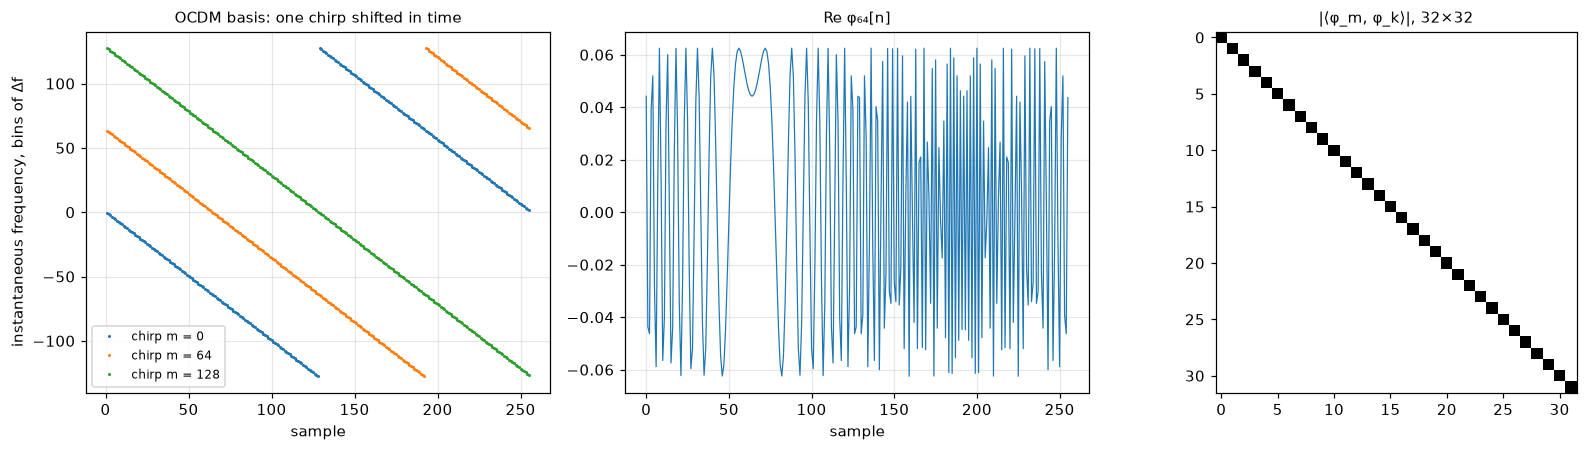

Orthogonality: max|⟨φ_m, φ_k⟩ − δ_mk| = 1.1e-14
Each chirp sweeps the whole band N·Δf = 3.84 MHz in N/f_s = 66.7 µs: chirp rate Δf² = 0.225 GHz/s


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for m in (0, 64, 128):
    c = PHI.conj()[m]
    inst = np.diff(np.unwrap(np.angle(c))) / (2 * np.pi) * N
    ax[0].plot(n_[1:], (inst + N / 2) % N - N / 2, ".", ms=2, label=f"chirp m = {m}")
ax[0].set_xlabel("sample"); ax[0].set_ylabel("instantaneous frequency, bins of Δf"); ax[0].legend(fontsize=8)
ax[0].set_title("OCDM basis: one chirp shifted in time", fontsize=10)
ax[1].plot(n_, PHI.conj()[64].real, lw=0.8)
ax[1].set_xlabel("sample"); ax[1].set_title("Re φ₆₄[n]", fontsize=10)
G = PHI.conj() @ PHI.T
ax[2].imshow(np.abs(G[:32, :32]), cmap="Greys"); ax[2].set_title("|⟨φ_m, φ_k⟩|, 32×32", fontsize=10); ax[2].grid(False)
plt.tight_layout(); plt.show()
print(f"Orthogonality: max|⟨φ_m, φ_k⟩ − δ_mk| = {np.max(np.abs(G - np.eye(N))):.1e}")
print(f"Each chirp sweeps the whole band N·Δf = {FS/1e6:.2f} MHz in N/f_s = {N/FS*1e6:.1f} µs: chirp rate Δf² = {(FS/N)**2/1e9:.3f} GHz/s")

## 2. The channel in the chirp domain: OCDM = SC-FDE with a unitary precoder
With a CP, the multipath channel is a circulant $H=F^H\Lambda F$. Since $\Phi=F^H\Gamma F$ and the diagonal $\Gamma,\Lambda$ commute,
$$\Phi H\Phi^H=F^H\Gamma\Lambda\Gamma^HF=F^H\Lambda F=H .$$
In the chirp domain the channel is **the same circulant**: a delay of $l$ samples simply moves chirp $m$ to chirp $m+l$. The receiver is a frequency-domain equalizer, as in SC-FDE: $\hat x=\Phi F^H\frac{\Lambda^*}{|\Lambda|^2+N_0}Fr$.

This gives an exact statement. The post-MMSE error covariance of OCDM, $\Phi(F^HDF)\Phi^H=F^HDF$, is **the same** as for SC-FDE, with $D=\mathrm{diag}\big(N_0/(|\Lambda_k|^2+N_0)\big)$. In OFDM the error of symbol $k$ is $D_k$: almost 1 on a subcarrier in a fade, almost 0 on a good one. In OCDM and SC-FDE every symbol gets the **mean** $\frac1N\sum_kD_k$. That is frequency diversity without a code.

The channel in the chirp domain Φ·H·Φᴴ equals H itself (circulants commute with Φ = FᴴΓF): max|Φ H Φᴴ − H| = 1.4e-14


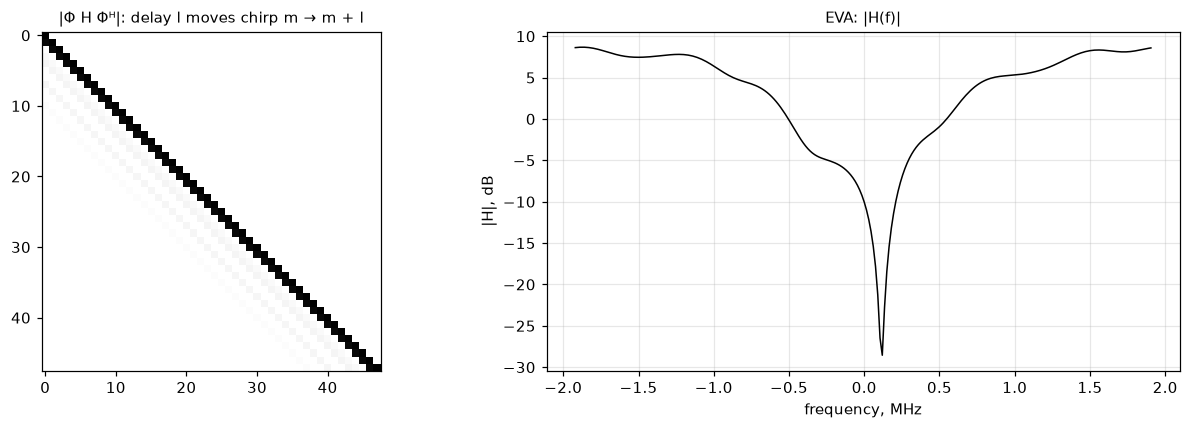

MMSE error covariance: OCDM Φ(FᴴDF)Φᴴ vs SC-FDE FᴴDF: max difference 1.5e-15; for OFDM the error variance is D's diagonal itself (from 0.013 to 0.986), for OCDM every symbol gets 0.110 = the mean


In [4]:
h = taps(PROFILE, np.random.default_rng(3), 1)[0]
Hc = np.array([np.roll(np.r_[h, np.zeros(N - L_CP)], k) for k in range(N)]).T   # circulant: column k is h shifted by k
Hocdm = PHI @ Hc @ PHI.conj().T
print(f"The channel in the chirp domain Φ·H·Φᴴ equals H itself (circulants commute with Φ = FᴴΓF): max|Φ H Φᴴ − H| = {np.max(np.abs(Hocdm - Hc)):.1e}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(np.abs(Hocdm[:48, :48]), cmap="Greys"); ax[0].grid(False)
ax[0].set_title("|Φ H Φᴴ|: delay l moves chirp m → m + l", fontsize=10)
_, x = qpsk_bits(1, rng)
Hf = np.fft.fft(h, N)
ax[1].plot(np.fft.fftshift(np.fft.fftfreq(N, 1 / FS)) / 1e6, 20 * np.log10(np.abs(np.fft.fftshift(Hf))), "k", lw=1)
ax[1].set_xlabel("frequency, MHz"); ax[1].set_ylabel("|H|, dB"); ax[1].set_title(f"{PROFILE}: |H(f)|", fontsize=10)
plt.tight_layout(); plt.show()
# error covariance after MMSE: identical for OCDM and SC-FDE
n0 = 0.1
D = np.diag(n0 / (np.abs(Hf)**2 + n0))
C_sc = F.conj().T @ D @ F
C_oc = PHI @ C_sc @ PHI.conj().T
print(f"MMSE error covariance: OCDM Φ(FᴴDF)Φᴴ vs SC-FDE FᴴDF: max difference {np.max(np.abs(C_oc - C_sc)):.1e}; for OFDM the error variance is D's diagonal itself (from {D.diagonal().real.min():.3f} to {D.diagonal().real.max():.3f}), for OCDM every symbol gets {np.real(C_oc[0,0]):.3f} = the mean")

## 3. BER in a multipath channel
Uncoded QPSK, EVA, channel static per block. One-tap OFDM sits on the Rayleigh theory ($\propto1/\bar\gamma$): each symbol is one subcarrier. OCDM and SC-FDE with MMSE coincide **point for point**, as section 2 promised, and fall much more steeply: an order of magnitude better at 20 dB, and no errors at 30 dB. The diversity order is bounded by the number of independent chunks of the band ($\sim N\Delta f/B_c$), and linear MMSE collects only part of it.

With a strong code and interleaving across subcarriers OFDM also collects this diversity (section 8 of `lte_sim`), so OCDM's advantage lies in the uncoded or lightly coded regime and in more uniform LLRs.

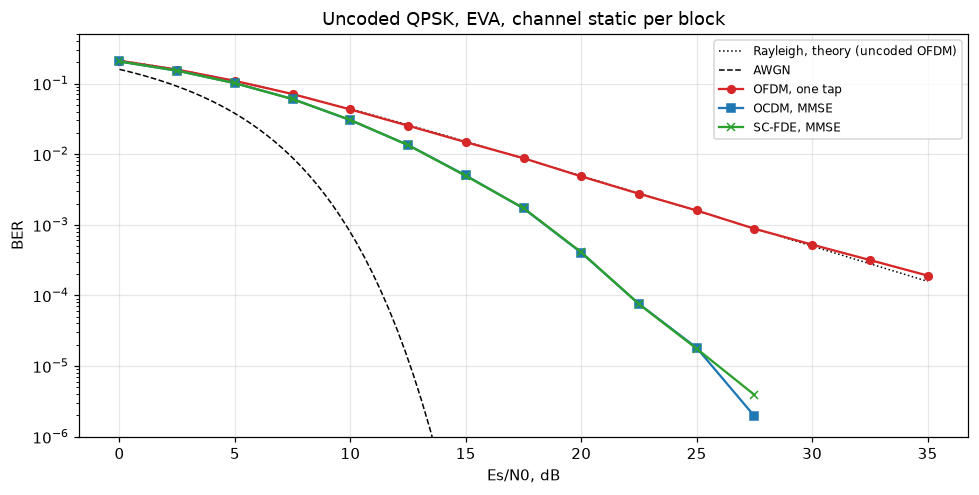

SNR 10 dB: OFDM 4.3e-02, OCDM 3.0e-02, SC-FDE 3.0e-02
SNR 20 dB: OFDM 4.8e-03, OCDM 4.0e-04, SC-FDE 4.1e-04
SNR 30 dB: OFDM 5.2e-04, OCDM 0.0e+00, SC-FDE 0.0e+00


In [5]:
snrs = np.arange(0, 36, 2.5)
ber = {k: [] for k in ("ofdm", "ocdm", "scfde")}
for snr in snrs:
    n0 = 10 ** (-snr / 10)
    b, x = qpsk_bits(BLOCKS, rng); h = taps(PROFILE, rng, BLOCKS)
    y, Hf = through(np.fft.ifft(x, axis=-1) * np.sqrt(N), h, n0, rng)          # OFDM
    ber["ofdm"].append(np.mean(hard_bits(np.fft.fft(y, axis=-1) / np.sqrt(N) / Hf) != b))
    y, Hf = through(ocdm_mod(x), h, n0, rng)
    ber["ocdm"].append(np.mean(hard_bits(ocdm_demod(fde_mmse(y, Hf, n0))) != b))
    y, Hf = through(x, h, n0, rng)                                              # single carrier + CP
    ber["scfde"].append(np.mean(hard_bits(fde_mmse(y, Hf, n0)) != b))
fig, a = plt.subplots(figsize=(9, 4.6))
sg = np.linspace(0, 35, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Rayleigh, theory (uncoded OFDM)")
a.semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
for (k, lab), c, mk in zip({"ofdm": "OFDM, one tap", "ocdm": "OCDM, MMSE", "scfde": "SC-FDE, MMSE"}.items(), ("C3", "C0", "C2"), ("o", "s", "x")):
    v = np.array(ber[k]); ok = v > 0
    a.semilogy(snrs[ok], v[ok], c + mk + "-", ms=5, label=lab)
a.set_ylim(1e-6, 0.5); a.set_xlabel("Es/N0, dB"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"Uncoded QPSK, {PROFILE}, channel static per block")
plt.tight_layout(); plt.show()
for i in (4, 8, 12):
    print(f"SNR {snrs[i]:.0f} dB: OFDM {ber['ofdm'][i]:.1e}, OCDM {ber['ocdm'][i]:.1e}, SC-FDE {ber['scfde'][i]:.1e}")

## 4. Partial-band interference
Interference of total power JSR occupies 10 % of the subcarriers; AWGN channel, SNR 20 dB.
- **OFDM**: the 10 % of symbols that are hit see SINR $1/(N_0+\text{JSR}/0.1)$, the rest are clean. BER ≈ $0.1\cdot\text{BER}(\text{SINR})$, saturating at 5 % for strong interference.
- **OCDM**: the unitary transform spreads the interference over all symbols, so **each** sees SINR = $1/(N_0+\text{JSR})$.

For weak interference (JSR < −6 dB) OCDM wins: the interference is diluted. For strong interference OFDM wins: it sacrifices a tenth of the symbols, while OCDM corrupts all of them. With a code the picture tilts further towards OFDM: hit subcarriers with correct (small) LLRs are simply erasures. Spreading without redundancy (rate 1) is **not** CDMA: there is no processing gain like in `cdma_sim` and `lora_sim`. Interference robustness is bought only by lowering the rate.

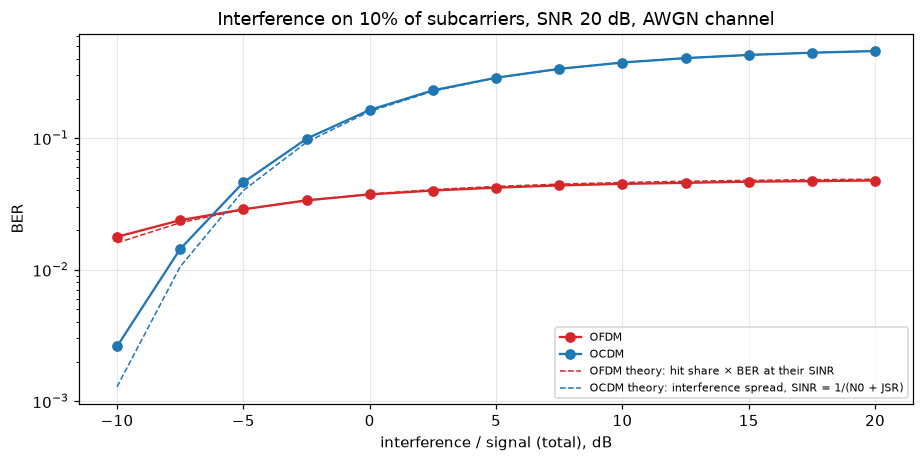

JSR 0 dB: OFDM 3.7e-02, OCDM 1.6e-01; the crossover is where BER(1/JSR) = share·½


In [6]:
# partial-band interference: OFDM loses the symbols on the hit subcarriers, OCDM spreads the interference over all of them
frac_jam, SNR_J = 0.1, 20
jsr = np.arange(-10, 21, 2.5)
r = {"ofdm": [], "ocdm": []}
for j in jsr:
    n0 = 10 ** (-SNR_J / 10)
    b, x = qpsk_bits(2000, rng)
    J = np.zeros(N); J[rng.choice(N, int(frac_jam * N), replace=False)] = 1
    Pj = 10 ** (j / 10) / frac_jam                               # the whole JSR interference power within a frac_jam share of the band
    noise_f = (np.sqrt(n0) + np.sqrt(Pj) * J) * crandn(x.shape, rng)        # noise + interference on the subcarriers
    # OFDM: Y = X + W_f
    r["ofdm"].append(np.mean(hard_bits(x + noise_f) != b))
    # OCDM: symbols → Φᴴ → FFT → +W_f → IFFT → Φ; the receiver knows the interference spectrum (no MMSE weighting needed, channel = 1)
    z = ocdm_demod(np.fft.ifft(np.fft.fft(ocdm_mod(x), axis=-1) / np.sqrt(N) + noise_f, axis=-1) * np.sqrt(N))
    r["ocdm"].append(np.mean(hard_bits(z) != b))
fig, a = plt.subplots(figsize=(8.5, 4.3))
for k, c in (("ofdm", "C3"), ("ocdm", "C0")):
    a.semilogy(jsr, r[k], c + "o-", label=k.upper())
th_ofdm = frac_jam * 0.5 * erfc(np.sqrt(0.5 / (10 ** (-SNR_J / 10) + 10 ** (jsr / 10) / frac_jam))) + (1 - frac_jam) * 0.5 * erfc(np.sqrt(0.5 * 10 ** (SNR_J / 10)))
th_ocdm = 0.5 * erfc(np.sqrt(0.5 / (10 ** (-SNR_J / 10) + 10 ** (jsr / 10))))
a.semilogy(jsr, th_ofdm, "C3--", lw=1, label="OFDM theory: hit share × BER at their SINR")
a.semilogy(jsr, th_ocdm, "C0--", lw=1, label="OCDM theory: interference spread, SINR = 1/(N0 + JSR)")
a.set_xlabel("interference / signal (total), dB"); a.set_ylabel("BER"); a.legend(fontsize=7)
a.set_title(f"Interference on {frac_jam:.0%} of subcarriers, SNR {SNR_J} dB, AWGN channel")
plt.tight_layout(); plt.show()
i0 = np.argmin(np.abs(jsr))
print(f"JSR 0 dB: OFDM {r['ofdm'][i0]:.1e}, OCDM {r['ocdm'][i0]:.1e}; the crossover is where BER(1/JSR) = share·½")

## 5. Doppler: where OCDM breaks
With Doppler the channel is no longer circulant, and $\Phi H\Phi^H\neq H$. For a chirp of slope $\Delta f^2$ a frequency shift by $\nu$ is equivalent to a time shift: a Doppler of $\alpha$ bins moves chirp $m$ to $m+\alpha$ — **the same place as a delay** $l=\alpha$. Paths with different $(l,\alpha)$ but the same $l+\alpha$ add up in one sample and lose diversity. This is the delay–Doppler coupling familiar from LoRa (where it hampers synchronization, section 3 of `lora_sim`).

- **OCDM with a frequency-domain equalizer** (as if the channel were static) — an error floor from inter-chirp interference, like OFDM's ICI floor.
- **OCDM with full LMMSE** over the channel matrix — the floor disappears and the curve is steep: most of the path diversity is still collected, but $l+\alpha$ collisions take away part of it.

AFDM (the next notebook) chooses the slope $c_1$ so that the values $\alpha+2Nc_1\,l$ never coincide. Then each path occupies its own samples, and the diversity is full.

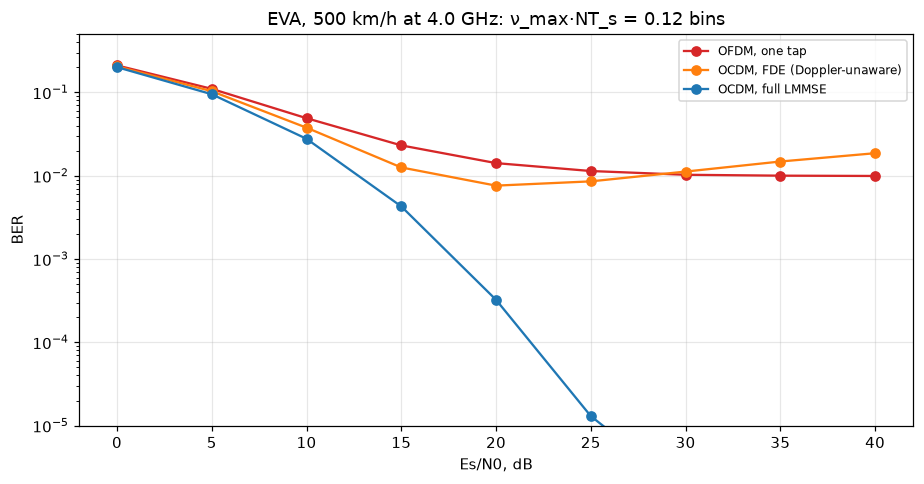

ofdm     : BER at 20 / 30 / 40 dB = 1.4e-02 / 1.0e-02 / 9.9e-03
ocdm     : BER at 20 / 30 / 40 dB = 3.2e-04 / 1.6e-06 / 0.0e+00
ocdm_fde : BER at 20 / 30 / 40 dB = 7.6e-03 / 1.1e-02 / 1.9e-02


In [7]:
# Doppler: a time-varying channel, EVA paths with Doppler ν_max·cos θ
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
def tv_matrix(rng, name=PROFILE):
    """N×N matrix "sent block → received" with CP, each path with its own Doppler"""
    t, p = PROFILES[name]; p = 10 ** (np.array(p) / 10); p /= p.sum()
    d = np.round(np.array(t) * 1e-9 * FS).astype(int)
    Hm = np.zeros((N, N), complex)
    for di, pi in zip(d, p):
        nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi)); g = np.sqrt(pi) * crandn((), rng)
        Hm += g * np.diag(np.exp(2j * np.pi * nu * (n_ + L_CP) / FS)) @ np.roll(np.eye(N), di, 0)
    return Hm
snrs5 = np.arange(0, 41, 5); R = 300
r5 = {k: np.zeros(len(snrs5)) for k in ("ofdm", "ocdm", "ocdm_fde")}
for _ in range(R):
    Hm = tv_matrix(rng)
    Ho = F @ Hm @ F.conj().T; Hc = PHI @ Hm @ PHI.conj().T
    b, x = qpsk_bits(4, rng)
    for i, snr in enumerate(snrs5):
        n0 = 10 ** (-snr / 10)
        w = np.sqrt(n0) * crandn(x.shape, rng)
        yo = x @ Ho.T + w
        r5["ofdm"][i] += np.mean(hard_bits(yo / np.diag(Ho)) != b)
        yc = x @ Hc.T + w
        z = np.linalg.solve(Hc.conj().T @ Hc + n0 * np.eye(N), Hc.conj().T @ yc.T).T
        r5["ocdm"][i] += np.mean(hard_bits(z) != b)
        Hf = np.diag(Ho)                                         # "as if the channel were static": FDE using the diagonal
        zf = (yc @ PHI.conj()) @ F.T                              # to frequency
        r5["ocdm_fde"][i] += np.mean(hard_bits(((zf * np.conj(Hf) / (np.abs(Hf)**2 + n0)) @ F.conj().T) @ PHI.T) != b)
r5 = {k: v / R for k, v in r5.items()}
fig, a = plt.subplots(figsize=(8.5, 4.5))
for (k, lab), c in zip({"ofdm": "OFDM, one tap", "ocdm_fde": "OCDM, FDE (Doppler-unaware)", "ocdm": "OCDM, full LMMSE"}.items(), ("C3", "C1", "C0")):
    ok = r5[k] > 0
    a.semilogy(snrs5[ok], r5[k][ok], c + "o-", label=lab)
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, dB"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"{PROFILE}, {SPEED_KMH} km/h at {FC_GHZ} GHz: ν_max·NT_s = {NU_MAX*N/FS:.2f} bins")
plt.tight_layout(); plt.show()
for k in r5:
    print(f"{k:9}: BER at 20 / 30 / 40 dB = {r5[k][4]:.1e} / {r5[k][6]:.1e} / {r5[k][8]:.1e}")

## 6. Peak-to-average power
OCDM is a sum of $N$ chirps with random phases and is Gaussian by the CLT: its PAPR is like OFDM's (~11 dB at 0.1 %). A single carrier (SC-FDE) is 3–4 dB lower. That is why on the uplink, where amplifier efficiency matters, SC-FDE/SC-FDMA is preferable: with MMSE reception it gives **the same** BER as OCDM (section 3).

OFDM      : PAPR exceeded by 0.1 % of blocks 11.3 dB
OCDM      : PAPR exceeded by 0.1 % of blocks 11.1 dB


SC (QPSK) : PAPR exceeded by 0.1 % of blocks 7.7 dB


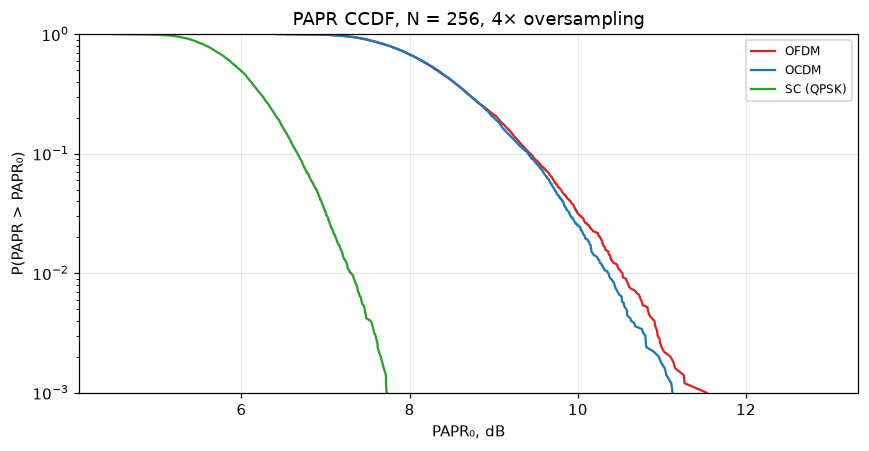

In [8]:
def papr(s):
    p = np.abs(s)**2
    return 10 * np.log10(p.max(-1) / p.mean(-1))
B = 5000; _, x = qpsk_bits(B, rng)
OS = 4
def up(s):
    S = np.fft.fft(s, axis=-1); G = np.zeros((len(s), N * OS), complex)
    G[:, :N // 2] = S[:, :N // 2]; G[:, -N // 2:] = S[:, -N // 2:]
    return np.fft.ifft(G, axis=-1)
fig, a = plt.subplots(figsize=(8, 4.2))
for k, s, c in (("OFDM", np.fft.ifft(x, axis=-1), "C3"), ("OCDM", ocdm_mod(x), "C0"), ("SC (QPSK)", x, "C2")):
    p = np.sort(papr(up(s)))
    a.semilogy(p, 1 - np.arange(B) / B, c, label=k)
    print(f"{k:10}: PAPR exceeded by 0.1 % of blocks {np.quantile(p, 0.999):.1f} dB")
a.set_ylim(1e-3, 1); a.set_xlabel("PAPR₀, dB"); a.set_ylabel("P(PAPR > PAPR₀)"); a.legend(fontsize=8)
a.set_title(f"PAPR CCDF, N = {N}, 4× oversampling")
plt.tight_layout(); plt.show()

## Comparison: OFDM, SC-FDE, OCDM, LoRa
| | OFDM | SC-FDE | OCDM | LoRa (CSS) |
|---|---|---|---|---|
| Basis | tones | impulses (deltas) | chirps, $\Phi=F^H\Gamma F$ | $2^{SF}$ shifts of one chirp, **one** per symbol |
| Rate | $N$ symbols per block | $N$ | $N$ | $SF$ bits per $2^{SF}$ samples |
| Equalizer (static channel) | one division per subcarrier | frequency-domain MMSE | frequency-domain MMSE (the same) | none (non-coherent reception) |
| Uncoded diversity | 1 | frequency, via MMSE | **the same as SC-FDE** | a large processing gain |
| Narrowband interference | knocks out its subcarriers | spread out | spread out | suppressed by spreading |
| Doppler | ICI | inter-symbol | delay–Doppler coupling | shifts the symbol (CFO = shift) |
| PAPR | Gaussian | low | Gaussian | constant envelope |

OCDM is a neat example of the fact that, in a channel with a CP, a waveform is just a unitary precoder on top of OFDM, and with linear reception all that matters is how it "mixes" the subcarriers. Without Doppler, chirps are no better than a single carrier. OCDM becomes interesting in a doubly dispersive channel and in radar (the chirp is the classic radar pulse). That is exactly where AFDM generalizes it.

## Things to try
- `PROFILE = "EPA"` — a wider coherence bandwidth, less diversity: the OCDM and OFDM curves in section 3 move closer; `"ETU"` — they move further apart
- `N = 64` (same $f_s$) — fewer independent chunks of band, and the OCDM/OFDM gap shrinks
- in section 4 `frac_jam = 0.5` — the point where OFDM and OCDM swap places moves
- `SPEED_KMH = 120` — in section 5 OCDM with a frequency-domain equalizer barely suffers: inter-chirp interference falls as $(\nu T)^2$
- in section 5 give every path the same Doppler $\alpha$ — paths whose $l+\alpha$ coincide merge, and OCDM LMMSE loses slope